# Import Libraries

In [1]:
import numpy as np
import pickle
import cv2
from os import listdir
from keras.models import Sequential
from sklearn.preprocessing import LabelBinarizer
from keras.layers.convolutional import Conv2D
from keras.layers.convolutional import MaxPooling2D
from keras.layers.core import Activation, Flatten, Dropout, Dense
from keras import backend as K
from keras.preprocessing.image import ImageDataGenerator
from keras.optimizers import Adam
from keras.preprocessing import image
from keras.preprocessing.image import img_to_array
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

Using TensorFlow backend.


# Load Dataset from local drive

In [2]:
EPOCHS =75
INIT_LR = 0.001
BS = 32
default_image_size = tuple((150, 150))
directory_root = r"C:\Users\<user>\Music\PlantVillage"
width=150
height=150
depth=3

In [3]:
def convert_image_to_array(image_dir):
    try:
        image = cv2.imread(image_dir)
        if image is not None :
            image = cv2.resize(image, default_image_size)   
            return img_to_array(image)
        else :
            return np.array([])
    except Exception as e:
        print(f"Error : {e}")
        return None

In [4]:
image_list, label_list = [], []

try:
    print("[INFO] Loading images ...")
    root_dir = listdir(directory_root)
    for directory in root_dir :
        # remove .DS_Store from list
        if directory == ".DS_Store" :
            root_dir.remove(directory)

    for plant_folder in root_dir :
        plant_disease_folder_list = listdir(f"{directory_root}/{plant_folder}")
        
        for disease_folder in plant_disease_folder_list :
            # remove .DS_Store from list
            if disease_folder == ".DS_Store" :
                plant_disease_folder_list.remove(disease_folder)

        for plant_disease_folder in plant_disease_folder_list:
            print(f"[INFO] Processing {plant_disease_folder}  ...")
            plant_disease_image_list = listdir(f"{directory_root}/{plant_folder}/{plant_disease_folder}/")
                
            for single_plant_disease_image in plant_disease_image_list :
                if single_plant_disease_image == ".DS_Store" :
                    plant_disease_image_list.remove(single_plant_disease_image)

            for image in plant_disease_image_list[:]:
                image_directory = f"{directory_root}/{plant_folder}/{plant_disease_folder}/{image}"
                if image_directory.endswith(".jpg") == True or image_directory.endswith(".JPG") == True:
                    image_list.append(convert_image_to_array(image_directory))
                    label_list.append(plant_disease_folder)
    print("[INFO] Image loading completed")  
except Exception as e:
    print(f"Error : {e}")

[INFO] Loading images ...
[INFO] Processing Tomato_Bacterial_spot  ...
[INFO] Processing Tomato_healthy  ...
[INFO] Processing Tomato_Late_blight  ...
[INFO] Processing Tomato_Septoria_leaf_spot  ...
[INFO] Processing Tomato_Spider_mites_Two_spotted_spider_mite  ...
[INFO] Processing Tomato__Target_Spot  ...
[INFO] Image loading completed


# Image preprocessing

In [5]:
# Total number of images 
image_size = len(image_list)
print(image_size,"total images")



10477 total images


In [6]:
label_binarizer = LabelBinarizer()
image_labels = label_binarizer.fit_transform(label_list)
pickle.dump(label_binarizer,open('label_transform.pkl', 'wb'))
n_classes = len(label_binarizer.classes_)
print(n_classes,"classes")

6 classes


In [7]:
print(label_binarizer.classes_)

['Tomato_Bacterial_spot' 'Tomato_Late_blight' 'Tomato_Septoria_leaf_spot'
 'Tomato_Spider_mites_Two_spotted_spider_mite' 'Tomato__Target_Spot'
 'Tomato_healthy']


In [8]:
np_image_list = np.array(image_list, dtype=np.float32) / 225.0


In [9]:
print("[INFO] Spliting data to train, test and validation")
x_train, x_test, y_train, y_test = train_test_split(np_image_list, image_labels, test_size=0.1, random_state = 42)
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, stratify = y_train)


[INFO] Spliting data to train, test and validation


In [10]:
aug = ImageDataGenerator(
    rotation_range=25, width_shift_range=0.1,
    height_shift_range=0.1, shear_range=0.2, 
    zoom_range=0.2,horizontal_flip=True, 
    fill_mode="nearest")
val_batches=aug.flow(x_val, y_val, batch_size=BS)

# CNN Parameter Building

In [11]:
# CNN building.
model = Sequential()
input_shape=(150, 150, 3)
model.add(Conv2D(32, (5, 5),input_shape=input_shape,activation='relu'))
model.add(MaxPooling2D(pool_size=(3, 3)))
model.add(Conv2D(32, (3, 3),activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Conv2D(64, (3, 3),activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))   
model.add(Flatten())
model.add(Dense(512,activation='relu'))
model.add(Dropout(0.25))
model.add(Dense(128,activation='relu'))          
model.add(Dense(n_classes,activation='softmax'))
model.summary()

W0126 11:34:17.393351 13688 deprecation_wrapper.py:119] From C:\Users\<user>\Anaconda3\lib\site-packages\keras\backend\tensorflow_backend.py:74: The name tf.get_default_graph is deprecated. Please use tf.compat.v1.get_default_graph instead.

W0126 11:34:26.446396 13688 deprecation_wrapper.py:119] From C:\Users\<user>\Anaconda3\lib\site-packages\keras\backend\tensorflow_backend.py:517: The name tf.placeholder is deprecated. Please use tf.compat.v1.placeholder instead.

W0126 11:34:32.660275 13688 deprecation_wrapper.py:119] From C:\Users\<user>\Anaconda3\lib\site-packages\keras\backend\tensorflow_backend.py:4138: The name tf.random_uniform is deprecated. Please use tf.random.uniform instead.

W0126 11:34:39.212096 13688 deprecation_wrapper.py:119] From C:\Users\<user>\Anaconda3\lib\site-packages\keras\backend\tensorflow_backend.py:3976: The name tf.nn.max_pool is deprecated. Please use tf.nn.max_pool2d instead.

W0126 11:34:41.756499 13688 deprecation_wrapper.py:119] From C:\Users\<user

_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_1 (Conv2D)            (None, 146, 146, 32)      2432      
_________________________________________________________________
max_pooling2d_1 (MaxPooling2 (None, 48, 48, 32)        0         
_________________________________________________________________
conv2d_2 (Conv2D)            (None, 46, 46, 32)        9248      
_________________________________________________________________
max_pooling2d_2 (MaxPooling2 (None, 23, 23, 32)        0         
_________________________________________________________________
conv2d_3 (Conv2D)            (None, 21, 21, 64)        18496     
_________________________________________________________________
max_pooling2d_3 (MaxPooling2 (None, 10, 10, 64)        0         
_________________________________________________________________
flatten_1 (Flatten)          (None, 6400)              0         
__________

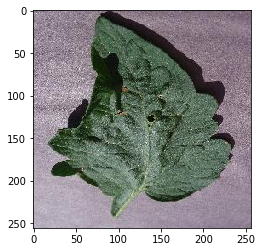

In [12]:
# Take one image to visualize it's changes after every layer
from keras.preprocessing import image
import numpy as np
img1 = image.load_img(r'C:\Users\<user>\Music\PlantVillage\PlantVillage\Tomato__Target_Spot\0a2de4c5-d688-4f9d-9107-ace1d281c307___Com.G_TgS_FL 7941.JPG')
plt.imshow(img1);

#preprocess image
img1 = image.load_img(r'C:\Users\<user>\Music\PlantVillage\PlantVillage\Tomato__Target_Spot\0a2de4c5-d688-4f9d-9107-ace1d281c307___Com.G_TgS_FL 7941.JPG', target_size=(150, 150))
img = image.img_to_array(img1)
img = img/255
img = np.expand_dims(img, axis=0)

In [13]:
# Visualizing output after every layer.
from keras.models import Model
conv2d_1_output = Model(inputs=model.input, outputs=model.get_layer('conv2d_1').output)
max_pooling2d_1_output = Model(inputs=model.input,outputs=model.get_layer('max_pooling2d_1').output)
conv2d_2_output = Model(inputs=model.input,outputs=model.get_layer('conv2d_2').output)
max_pooling2d_2_output = Model(inputs=model.input,outputs=model.get_layer('max_pooling2d_2').output)
conv2d_3_output = Model(inputs=model.input,outputs=model.get_layer('conv2d_3').output)
max_pooling2d_3_output = Model(inputs=model.input,outputs=model.get_layer('max_pooling2d_3').output)
flatten_1_output = Model(inputs=model.input,outputs=model.get_layer('flatten_1').output)
conv2d_1_features = conv2d_1_output.predict(img)
max_pooling2d_1_features = max_pooling2d_1_output.predict(img)
conv2d_2_features = conv2d_2_output.predict(img)
max_pooling2d_2_features = max_pooling2d_2_output.predict(img)
conv2d_3_features = conv2d_3_output.predict(img)
max_pooling2d_3_features = max_pooling2d_3_output.predict(img)
flatten_1_features = flatten_1_output.predict(img)

W0126 11:35:42.404416 13688 deprecation_wrapper.py:119] From C:\Users\<user>\Anaconda3\lib\site-packages\keras\backend\tensorflow_backend.py:2741: The name tf.Session is deprecated. Please use tf.compat.v1.Session instead.



# Visualizing The Image After Every Layer

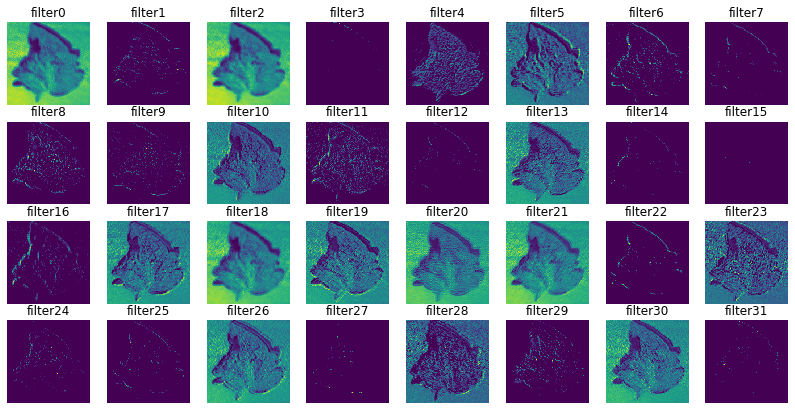

In [14]:
import matplotlib.image as mpimg

fig=plt.figure(figsize=(14,7))
columns = 8
rows = 4
for i in range(columns*rows):
    #img = mpimg.imread()
    fig.add_subplot(rows, columns, i+1)
    plt.axis('off')
    plt.title('filter'+str(i))
    plt.imshow(conv2d_1_features[0, :, :, i], cmap='viridis') # Visualizing in color mode.
plt.show()

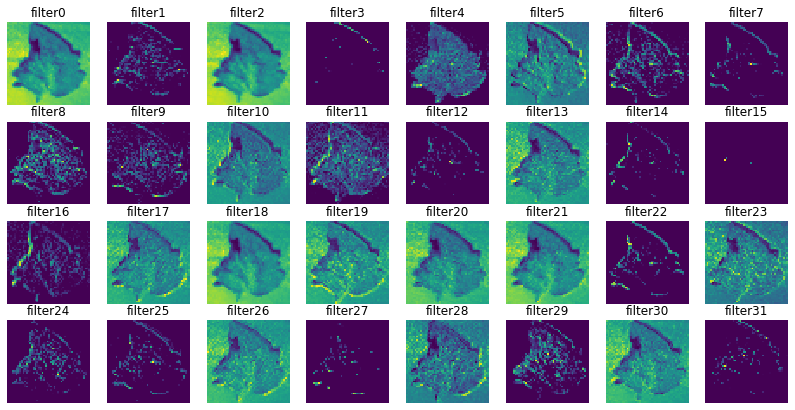

In [15]:
import matplotlib.image as mpimg

fig=plt.figure(figsize=(14,7))
columns = 8
rows = 4
for i in range(columns*rows):
    #img = mpimg.imread()
    fig.add_subplot(rows, columns, i+1)
    plt.axis('off')
    plt.title('filter'+str(i))
    plt.imshow(max_pooling2d_1_features[0, :, :, i], cmap='viridis')
plt.show()

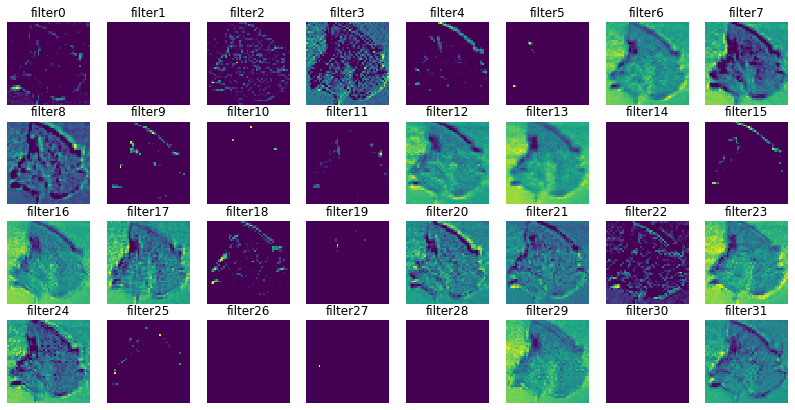

In [16]:
import matplotlib.image as mpimg

fig=plt.figure(figsize=(14,7))
columns = 8
rows = 4
for i in range(columns*rows):
    #img = mpimg.imread()
    fig.add_subplot(rows, columns, i+1)
    plt.axis('off')
    plt.title('filter'+str(i))
    plt.imshow(conv2d_2_features[0, :, :, i], cmap='viridis')
plt.show()

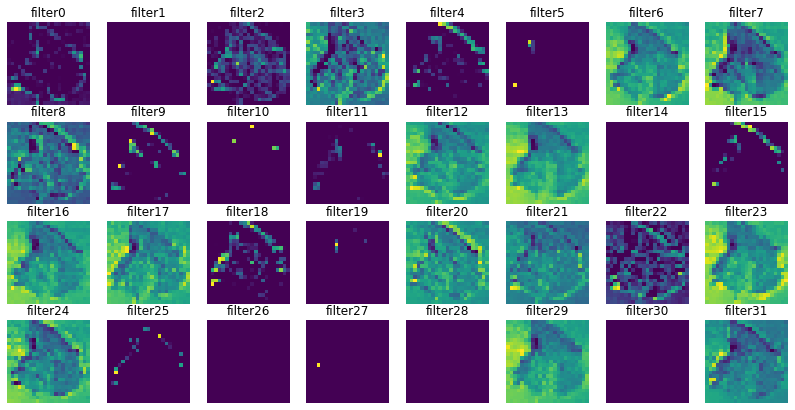

In [17]:
# we can also visualize in color mode.
import matplotlib.image as mpimg

fig=plt.figure(figsize=(14,7))
columns = 8
rows = 4
for i in range(columns*rows):
    #img = mpimg.imread()
    fig.add_subplot(rows, columns, i+1)
    plt.axis('off')
    plt.title('filter'+str(i))
    plt.imshow(max_pooling2d_2_features[0, :, :, i], cmap='viridis') 
plt.show()

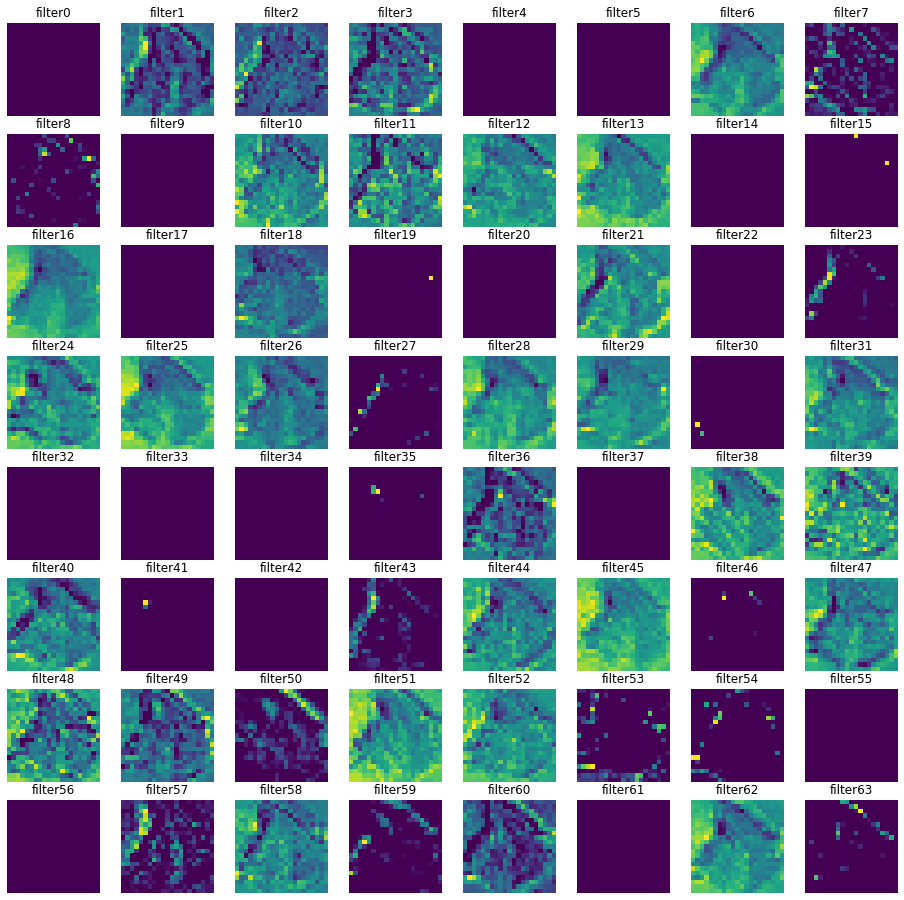

In [18]:
import matplotlib.image as mpimg

fig=plt.figure(figsize=(16,16))
columns =8 
rows = 8
for i in range(columns*rows):
    #img = mpimg.imread()
    fig.add_subplot(rows, columns, i+1)
    plt.axis('off')
    plt.title('filter'+str(i))
    plt.imshow(conv2d_3_features[0, :, :, i], cmap='viridis')
plt.show()

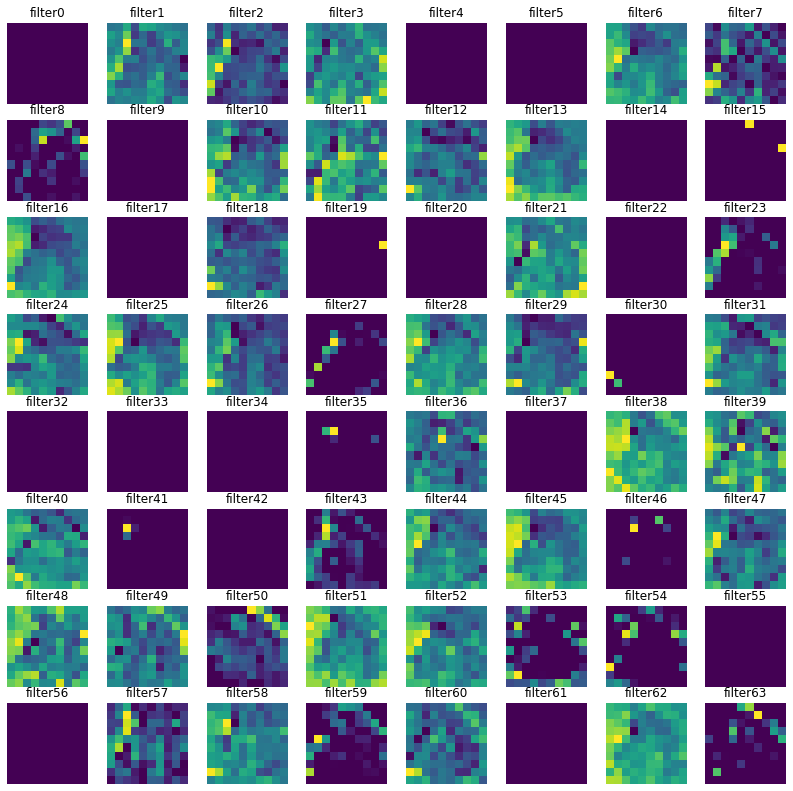

In [19]:
import matplotlib.image as mpimg

fig=plt.figure(figsize=(14,14))
columns = 8
rows = 8
for i in range(columns*rows):
    #img = mpimg.imread()
    fig.add_subplot(rows, columns, i+1)
    plt.axis('off')
    plt.title('filter'+str(i))
    plt.imshow(max_pooling2d_3_features[0, :, :, i],cmap='viridis')
plt.show()

# Training The Model

In [20]:
opt = Adam(lr=INIT_LR, decay=INIT_LR / EPOCHS)
# distribution
model.compile(loss="categorical_crossentropy", optimizer=opt,metrics=["accuracy"])
# train the network
print("[INFO] training network...")

W0126 11:36:18.309830 13688 deprecation_wrapper.py:119] From C:\Users\<user>\Anaconda3\lib\site-packages\keras\optimizers.py:790: The name tf.train.Optimizer is deprecated. Please use tf.compat.v1.train.Optimizer instead.



[INFO] training network...


In [21]:
history = model.fit_generator(
    aug.flow(x_train, y_train, batch_size=BS),
    validation_data=val_batches,
    steps_per_epoch=236,
    validation_steps=59,
    epochs=EPOCHS, verbose=1
    )

W0126 11:36:19.221200 13688 deprecation.py:323] From C:\Users\<user>\Anaconda3\lib\site-packages\tensorflow\python\ops\math_grad.py:1250: add_dispatch_support.<locals>.wrapper (from tensorflow.python.ops.array_ops) is deprecated and will be removed in a future version.
Instructions for updating:
Use tf.where in 2.0, which has the same broadcast rule as np.where


Epoch 1/75
236/236 [==============================] - 553s 2s/step - loss: 1.3020 - acc: 0.4680 - val_loss: 0.7408 - val_acc: 0.7174
Epoch 2/75
236/236 [==============================] - 361s 2s/step - loss: 0.7088 - acc: 0.7340 - val_loss: 0.7481 - val_acc: 0.7206
Epoch 3/75
236/236 [==============================] - 416s 2s/step - loss: 0.5512 - acc: 0.8016 - val_loss: 0.5368 - val_acc: 0.8070
Epoch 4/75
236/236 [==============================] - 348s 1s/step - loss: 0.4556 - acc: 0.8336 - val_loss: 0.4787 - val_acc: 0.8261
Epoch 5/75
236/236 [==============================] - 325s 1s/step - loss: 0.3960 - acc: 0.8561 - val_loss: 0.3237 - val_acc: 0.8738
Epoch 6/75
236/236 [==============================] - 367s 2s/step - loss: 0.3559 - acc: 0.8720 - val_loss: 0.2728 - val_acc: 0.9014
Epoch 7/75
236/236 [==============================] - 315s 1s/step - loss: 0.3017 - acc: 0.8944 - val_loss: 0.3031 - val_acc: 0.8812
Epoch 8/75
236/236 [==============================] - 410s 2s/step - 

# Plot For Accuracy And Losses

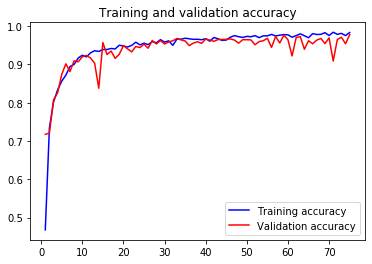

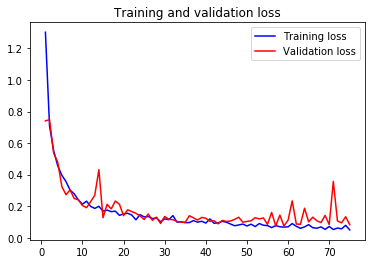

In [22]:
acc=history.history['acc']
val_acc=history.history['val_acc']
loss=history.history['loss']
val_loss=history.history['val_loss']
epochs=range(1,len(acc)+1)
#Train and validation accuracy
plt.plot(epochs,acc,'b',label='Training accuracy')
plt.plot(epochs,val_acc,'r',label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.legend()

plt.figure()
#Train and validation loss
plt.plot(epochs,loss,'b',label='Training loss')
plt.plot(epochs,val_loss,'r',label='Validation loss')
plt.title('Training and validation loss')
plt.legend()
plt.show()

# Evaluate model using Test Dataset

In [23]:
print("[INFO] calculaing model accuracy")
scores=model.evaluate(x_test,y_test)
print(f"Test Accuracy:{scores[1]*100}")

[INFO] calculaing model accuracy
1048/1048 [==============================] - 15s 14ms/step
Test Accuracy:98.47328244274809


# Classification Images

In [24]:
#predicted results for first 10 images in test set
model.predict(x_test[:10])

array([[1.00000000e+00, 5.75619240e-12, 3.75696307e-10, 1.19330620e-14,
        1.18530408e-09, 2.45765224e-18],
       [2.65798561e-04, 4.73315267e-05, 9.39702022e-06, 1.73516184e-01,
        8.26125562e-01, 3.56879027e-05],
       [7.68540952e-19, 1.68095897e-13, 2.57057191e-18, 1.00000000e+00,
        2.99721670e-09, 2.11410377e-14],
       [1.40587386e-09, 1.89943009e-07, 9.99999762e-01, 1.36080279e-11,
        1.92055474e-08, 1.28485285e-08],
       [4.56781545e-23, 3.43709538e-15, 1.74920679e-22, 1.00000000e+00,
        8.11809370e-11, 3.19757729e-19],
       [1.41840692e-10, 1.91919986e-04, 1.36590742e-07, 6.95246812e-12,
        1.03008470e-11, 9.99808013e-01],
       [1.38541175e-11, 7.65540562e-07, 9.99998927e-01, 5.06086617e-10,
        2.55110194e-07, 6.54956693e-08],
       [5.80662570e-04, 9.14389968e-01, 8.50292966e-02, 5.17971870e-08,
        1.00644527e-07, 8.05884290e-14],
       [1.18120177e-19, 7.12033731e-12, 2.95111804e-22, 1.00000000e+00,
        3.30823541e-15, 

In [25]:
#actual results for first 10 images in test set
y_test[:10]


array([[1, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0, 0],
       [0, 0, 1, 0, 0, 0],
       [0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 1],
       [0, 0, 1, 0, 0, 0],
       [0, 1, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 1, 0]])

# Confusion matrix Results

In [26]:
from sklearn.metrics import classification_report, confusion_matrix
y_predictions = model.predict( x_test,verbose=0)
y_pred = np.argmax(y_predictions, axis=1)
 
for ix in range(6):
    print(ix, confusion_matrix(np.argmax(y_test,axis=1),y_pred)[ix].sum())
cm = confusion_matrix(np.argmax(y_test,axis=1),y_pred)
print(cm)

0 227
1 196
2 172
3 158
4 153
5 142
[[224   1   0   0   2   0]
 [  2 193   1   0   0   0]
 [  1   0 171   0   0   0]
 [  0   0   1 154   3   0]
 [  0   0   3   2 148   0]
 [  0   0   0   0   0 142]]


# Visualizing Confusion matrix

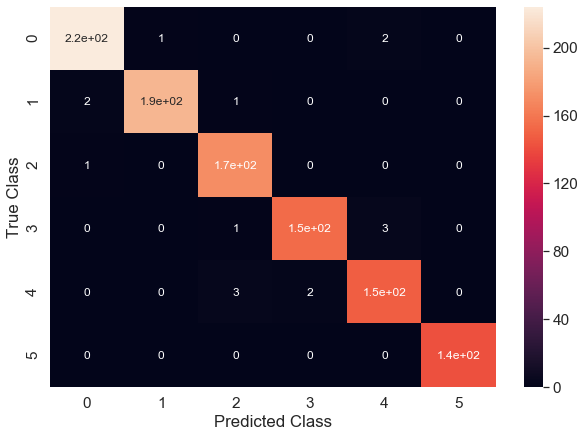

In [33]:
import seaborn as sn
import pandas  as pd
df_cm = pd.DataFrame(cm, range(6), range(6))
plt.figure(figsize = (10,7))
sn.set(font_scale=1.4)#for label size
sn.heatmap(df_cm, annot=True,annot_kws={"size": 12})# font size
# naming the x axis
plt.xlabel('Predicted Class')
# naming the y axis
plt.ylabel('True Class')
plt.show()

In [28]:
prediction = model.predict(x_test)

In [29]:
predictions = np.argmax(prediction, axis = 1)

In [30]:
y_test_labels = np.argmax(y_test, axis =1)

In [40]:
from sklearn.metrics import precision_recall_fscore_support as score

precision, recall, fscore, support = score(y_test_labels, predictions)

print('precision: {}'.format(precision))
print('recall:    {}'.format(recall))
print('fscore:    {}'.format(fscore))
print('FPR:      ', 1 - precision)
print('support:   {}'.format(support))

precision: [0.98678414 0.99484536 0.97159091 0.98717949 0.96732026 1.        ]
recall:    [0.98678414 0.98469388 0.99418605 0.97468354 0.96732026 1.        ]
fscore:    [0.98678414 0.98974359 0.98275862 0.98089172 0.96732026 1.        ]
FPR:       [0.01321586 0.00515464 0.02840909 0.01282051 0.03267974 0.        ]
support:   [227 196 172 158 153 142]
